# SHAP con XGBoost: ventas de Rossmann

Este notebook sigue el mismo recorrido que el ejemplo de SHAP con LightGBM, pero entrena un modelo **XGBoost** para predecir las ventas diarias de las tiendas Rossmann.

Veremos cómo interpretar una predicción individual y cómo resumir el efecto de las variables en muchas observaciones.

Fuente del modelo: [documentación de XGBoost](https://xgboost.readthedocs.io/)
Fuente de los datos: [Rossmann Store Sales en Kaggle](https://www.kaggle.com/competitions/rossmann-store-sales/data)


## 1. Ideas principales de XGBoost

XGBoost construye un conjunto de árboles de decisión de forma secuencial. Cada árbol nuevo busca corregir errores que dejaron los árboles anteriores.

- **Crecimiento por niveles:** los árboles se construyen nivel por nivel (con el método habitual `hist`).
- **Histogramas:** `tree_method='hist'` agrupa valores en bins para encontrar divisiones con mayor eficiencia.
- **Regularización:** parámetros como `reg_lambda`, `reg_alpha`, `gamma` y `max_depth` ayudan a controlar la complejidad.
- **Muestreo:** `subsample` y `colsample_bytree` reducen la fracción de filas y columnas usada en cada árbol.
- **Early stopping:** el entrenamiento puede detenerse si la métrica de validación deja de mejorar.

A diferencia de LightGBM, cuyo crecimiento habitual es *leaf-wise*, XGBoost normalmente crece por niveles. Ambos son métodos de gradient boosting con árboles, pero sus algoritmos y parámetros no son idénticos.


In [1]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


## 2. Carga y preparación de los datos

Coloca `rossman.csv` y `store.csv` en la misma carpeta que este notebook. Se ordenan las observaciones por fecha y se conservan solo los días en que la tienda estuvo abierta.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk

from xgboost import XGBRegressor, plot_importance
from sklearn.metrics import r2_score, mean_squared_error

# Cargar y combinar los datos de ventas y tiendas
train = pd.read_csv('rossman.csv', dtype={'StateHoliday': 'string'})
stores = pd.read_csv('store.csv')
df = pd.merge(train, stores, on='Store')

# Orden temporal y filtro de tiendas abiertas
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df = df[df['Open'] == 1].copy()

# Variables de calendario
df['month'] = df['Date'].dt.month
df['day_of_month'] = df['Date'].dt.day
df['week_of_year'] = df['Date'].dt.isocalendar().week.astype(int)

# No usamos identificadores ni información que revele directamente las ventas
df = df.drop(columns=['Date', 'Store', 'Customers', 'Open'])

print(f'Observaciones: {len(df):,}')
df.head()


Observaciones: 844,392


,DayOfWeek,Sales,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,month,day_of_month,week_of_year
1016447,2,3139,0,a,1,b,b,900.0,NaN,NaN,1,14.0,2013.0,"Feb,May,Aug,Nov",1,1,1
1016429,2,2401,0,a,1,b,a,90.0,NaN,NaN,1,31.0,2013.0,"Jan,Apr,Jul,Oct",1,1,1
1016606,2,2646,0,a,1,b,b,590.0,NaN,NaN,1,5.0,2013.0,"Mar,Jun,Sept,Dec",1,1,1
1016588,2,3113,0,a,1,b,a,1260.0,6.0,2011.0,0,NaN,NaN,NaN,1,1,1
1016624,2,2907,0,a,1,a,c,18160.0,NaN,NaN,0,NaN,NaN,NaN,1,1,1


## 3. Separación temporal y variables categóricas

Separamos los datos respetando el tiempo: 70% para entrenar, 20% para validar el entrenamiento y 10% final para evaluar. La validación se usa para `early stopping`; el conjunto de prueba queda al final para medir el desempeño.

Las categorías se convierten en columnas indicadoras. Después alineamos validación y prueba a las columnas creadas con entrenamiento.


In [3]:
target = 'Sales'
n = len(df)
i_train = int(n * 0.70)
i_valid = int(n * 0.90)

train_df = df.iloc[:i_train]
valid_df = df.iloc[i_train:i_valid]
test_df = df.iloc[i_valid:]

X_train = pd.get_dummies(train_df.drop(columns=target), drop_first=True)
y_train = train_df[target]
X_valid = pd.get_dummies(valid_df.drop(columns=target), drop_first=True)
y_valid = valid_df[target]
X_test = pd.get_dummies(test_df.drop(columns=target), drop_first=True)
y_test = test_df[target]

X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# XGBoost requiere nombres de columnas válidos para sus matrices
X_train.columns = X_train.columns.str.replace(r'[^\w]', '_', regex=True)
X_valid.columns = X_valid.columns.str.replace(r'[^\w]', '_', regex=True)
X_test.columns = X_test.columns.str.replace(r'[^\w]', '_', regex=True)

print(f'Entrenamiento: {X_train.shape}')
print(f'Validación:    {X_valid.shape}')
print(f'Prueba:        {X_test.shape}')


Entrenamiento: (591074, 22)
Validación:    (168878, 22)
Prueba:        (84440, 22)


## 4. Entrenamiento de XGBoost

`early_stopping_rounds` detiene el entrenamiento cuando el RMSE de validación no mejora durante 100 iteraciones. El conjunto final de prueba no participa en el ajuste.


In [4]:
model= XGBRegressor(n_estimators=3000,early_stopping_rounds=100,max_depth=6,learning_rate=0.1)
model.fit(X_train,y_train,eval_set=[(X_train,y_train),(X_valid,y_valid)],verbose=100)


#    eval_set=[(X_train, y_train), (X_valid, y_valid)], verbose=100


[0]	validation_0-rmse:2978.86782	validation_1-rmse:3137.53992
[100]	validation_0-rmse:1797.11086	validation_1-rmse:1976.11454
[200]	validation_0-rmse:1379.06281	validation_1-rmse:1616.65919
[300]	validation_0-rmse:1176.02601	validation_1-rmse:1452.03880
[400]	validation_0-rmse:1075.77128	validation_1-rmse:1384.14621
[500]	validation_0-rmse:1002.76809	validation_1-rmse:1344.70181
[600]	validation_0-rmse:953.87072	validation_1-rmse:1322.14199
[700]	validation_0-rmse:919.92829	validation_1-rmse:1305.18653
[800]	validation_0-rmse:893.67420	validation_1-rmse:1300.74745
[900]	validation_0-rmse:874.09305	validation_1-rmse:1291.60417
[1000]	validation_0-rmse:853.50750	validation_1-rmse:1278.81685
[1100]	validation_0-rmse:839.71616	validation_1-rmse:1272.53580
[1200]	validation_0-rmse:825.42594	validation_1-rmse:1266.86755
[1300]	validation_0-rmse:814.69482	validation_1-rmse:1269.34035
[1322]	validation_0-rmse:811.86111	validation_1-rmse:1268.04717


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=100,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=3000,
             n_jobs=None, num_parallel_tree=None, ...)

In [5]:
# Calcula el R2
y_pred=model.predict(X_test)
r2_score(y_pred=y_pred,y_true=y_test)


0.8598252534866333

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Calcular medias solo en train
mean_impute = X_train.mean()

# Aplicar a ambos usando las medias del train
X_train_filled = X_train.fillna(mean_impute)
X_test_filled = X_test.fillna(mean_impute)

# Entrenar modelo
linear_model = LinearRegression()
linear_model.fit(X_train_filled, y_train)

# Predecir
linear_predict = linear_model.predict(X_test_filled)

# Evaluar
r2_score(y_pred=linear_predict, y_true=y_test)


0.2088563452628217

## 5. Importancia de variables de XGBoost

La importancia `weight` que dice cuantas veces sale una variavle en el árbo, reamente no nos dice el peso o si es tan importsnte, para eso usamos SHAP.


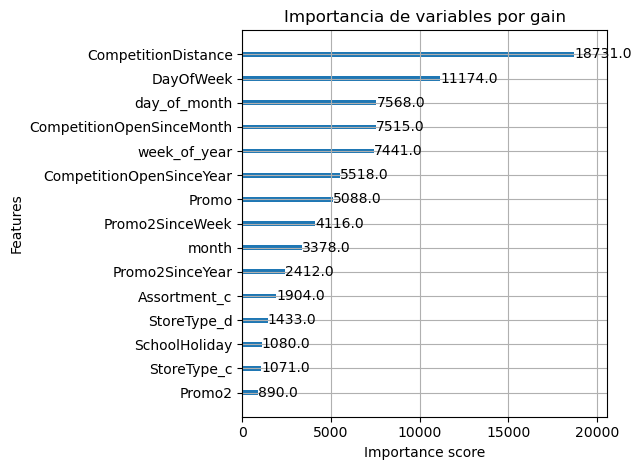

In [8]:
plot_importance(model, max_num_features=15, importance_type='weight')
plt.title('Importancia de variables por gain')
plt.tight_layout()
plt.show()


## 6. Calcular valores SHAP

Este ejemplo usa `shap.TreeExplainer`. Para que funcione con Python 3.10, usa SHAP 0.47.1 junto con XGBoost 3.0.2. XGBoost 3.1 cambió el formato del valor base y rompe la compatibilidad con esta versión de SHAP. Si necesitas instalar o ajustar las versiones, ejecuta `%pip install shap==0.47.1 xgboost==3.0.2` y reinicia el kernel antes de correr el notebook.

Calcularemos SHAP para una muestra de hasta 2,000 observaciones del conjunto de prueba.


In [ ]:
import shap

shap.initjs()

# sample de 2K

# Calcular SHAP
# shap.TreeExplainer(model)
# explainer.shap_values(X_shap)


## 7. Explicación de una predicción individual

El *waterfall plot* parte del valor base (la predicción esperada de referencia) y muestra cuánto empuja cada variable la predicción hacia arriba o hacia abajo para una observación.

Los valores SHAP están expresados en la misma escala que la salida del modelo: aquí, unidades de ventas.


In [ ]:
# Waterfall a partir del arreglo que devuelve explainer.shap_values
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_shap.iloc[0].to_numpy(),
        feature_names=X_shap.columns.tolist()
    ),
    max_display=15
)


## 8. Resumen global: magnitud media del efecto

Cada barra muestra el promedio del valor absoluto de SHAP para esa variable. Resume cuánto suele influir, sin distinguir si aumenta o disminuye la predicción.


In [ ]:
shap.summary_plot(shap_values, X_shap, plot_type='bar')

## 9. Resumen global: dirección y distribución

Cada punto representa una observación. El eje horizontal indica si el valor SHAP empuja la predicción hacia arriba o hacia abajo; el color representa el valor de la variable.


## 10. Efecto por variable

Los gráficos de dispersión muestran el valor de una variable en el eje horizontal y su valor SHAP en el vertical. Así se observa cómo cambia la contribución de esa variable entre observaciones.

El siguiente bloque dibuja las variables con mayor importancia SHAP media. Se puede cambiar `top_features` para revisar otras.


In [ ]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_importance = pd.Series(mean_abs_shap, index=X_shap.columns).sort_values(ascending=False)
top_features = shap_importance.head(10).index

for feature in top_features:
    plt.figure(figsize=(14, 8))
    shap.dependence_plot(feature, shap_values, X_shap, interaction_index=None, show=False)
    plt.title(f'Efecto individual de {feature}', fontsize=18)
    plt.tight_layout()
    plt.show()


## 11. Lectura de resultados

- El baseline es la predicción de referencia del modelo para la muestra de fondo.
- Cada valor SHAP indica cuánto contribuye una variable a mover una predicción desde ese baseline.
- En una explicación individual, baseline más la suma de los SHAP recupera la predicción del modelo (salvo pequeñas diferencias numéricas).
- En el resumen global, la importancia media absoluta muestra magnitud; el beeswarm también muestra dirección y dispersión.

SHAP describe cómo se comporta este modelo en los datos analizados. Las contribuciones no demuestran por sí solas relaciones causales.
